In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
from pathlib import Path

# Find the clean_sales.csv file automatically
csv_path = next(Path("..").rglob("clean_sales.csv"))

print("Using:", csv_path)

sales_df = pd.read_csv(csv_path)

# Remove non-sellable transactions
exclude_keywords = [
    "DEPOSIT",
    "RETURN",
    "REFUND",
    "RENTAL",
    "MISCELLANEOUS"
]

pattern = "|".join(exclude_keywords)

product_sales = sales_df[
    ~sales_df["description"].str.upper().str.contains(pattern, na=False)
].copy()

# Build product summary
product_summary = (
    product_sales
    .groupby(["inventory_number", "description"], as_index=False)
    .agg(
        total_quantity=("quantity_sold", "sum"),
        total_revenue=("total_price", "sum"),
        total_cost=("total_cost", "sum"),
        total_profit=("gross_profit", "sum"),
        transactions=("tx_number", "count")
    )
)

product_summary["profit_margin"] = (
    product_summary["total_profit"] /
    product_summary["total_revenue"]
)

product_summary.head()

In [ ]:
sales_df = pd.read_csv("../exports/clean_sales.csv")

sales_df.head()



,tx_number,inventory_number,description,quantity_sold,price,cost,total_price,total_cost,gross_profit,category,period,profit_margin
0,194142,00107,HIGH LIFE 7OZ NR CASE,1,17.49,13.65,17.49,13.65,3.84,1,5,0.219554
1,194944,00107,HIGH LIFE 7OZ NR CASE,1,17.49,13.65,17.49,13.65,3.84,1,5,0.219554
2,196770,00107,HIGH LIFE 7OZ NR CASE,1,17.49,13.65,17.49,13.65,3.84,1,5,0.219554
3,199190,00107,HIGH LIFE 7OZ NR CASE,1,17.49,13.65,17.49,13.65,3.84,1,5,0.219554
4,197536,00207,LITE 7OZ NR CASE,2,20.99,16.65,41.98,33.30,8.68,1,5,0.206765


In [ ]:
total_revenue = sales_df["total_price"].sum()
total_profit = sales_df["gross_profit"].sum()
total_quantity = sales_df["quantity_sold"].sum()

profit_margin = total_profit / total_revenue

print(f"Total Revenue: ${total_revenue:,.2f}")
print(f"Total Gross Profit: ${total_profit:,.2f}")
print(f"Total Quantity Sold: {total_quantity:,.0f}")
print(f"Overall Profit Margin: {profit_margin:.2%}")

Total Revenue: $230,063.19
Total Gross Profit: $50,801.46
Total Quantity Sold: 13,953
Overall Profit Margin: 22.08%


In [ ]:
top_revenue = product_summary.sort_values(
    by="total_revenue",
    ascending=False
)

top_revenue.head(20)

AttributeError: 'ellipsis' object has no attribute 'sort_values'

In [ ]:
top_profit = product_summary.sort_values(
    by="total_profit",
    ascending=False
)

top_profit.head(20)

,inventory_number,description,total_cases,total_revenue,total_profit,profit_margin
1,+30,KEG DEPOSIT,148,4440.00,4440.00,1.000000
24,00236,LITE 36PK,281,8822.02,2078.02,0.235549
89,10230U,MICHELOB ULTRA 30PK,176,5698.37,1515.97,0.266036
1567,I20,ICE 20# BAG,546,2479.54,1119.79,0.451612
1116,650941*8,SUPER LYTE VARIETY 8PK,185,3870.55,1097.40,0.283526
1115,650941,SUPER LYTE VARIETY 3/8 CAS,85,4899.15,1074.15,0.219252
1579,MT,MISCELLANEOUS TAXABLE,20,1070.21,1070.21,1.000000
0,+100,CO2 DEPOSIT,9,900.00,900.00,1.000000
718,35930,COORS LT 30PK,132,3918.68,860.88,0.219686
1418,9997,BUSCH LT APPLE 30PK,79,2351.21,771.21,0.328006


In [ ]:
top_cases = product_summary.sort_values(
    by="total_cases",
    ascending=False
)

top_cases.head(20)

,inventory_number,description,total_cases,total_revenue,total_profit,profit_margin
1585,NICKELROUNDINGNICKEL,ROUNDING,1337,1.14,1.14,1.000000
1567,I20,ICE 20# BAG,546,2479.54,1119.79,0.451612
24,00236,LITE 36PK,281,8822.02,2078.02,0.235549
1116,650941*8,SUPER LYTE VARIETY 8PK,185,3870.55,1097.40,0.283526
89,10230U,MICHELOB ULTRA 30PK,176,5698.37,1515.97,0.266036
1396,99,ALCOHOL SLUSHIE 16OZ CUP,154,726.17,468.99,0.645841
1568,I8,ICE 8# BAG,152,402.27,228.77,0.568698
1,+30,KEG DEPOSIT,148,4440.00,4440.00,1.000000
3,-30,KEG RETURN,133,-3990.00,-3990.00,1.000000
718,35930,COORS LT 30PK,132,3918.68,860.88,0.219686


In [ ]:
product_ranking = product_summary.copy()

product_ranking["total_revenue"] = product_ranking["total_revenue"].round(2)
product_ranking["total_profit"] = product_ranking["total_profit"].round(2)
product_ranking["profit_margin"] = (product_ranking["profit_margin"] * 100).round(2)

product_ranking = product_ranking.sort_values(
    by="total_revenue",
    ascending=False
)

product_ranking.head(25)

,inventory_number,description,total_cases,total_revenue,total_profit,profit_margin
24,00236,LITE 36PK,281,8822.02,2078.02,23.55
89,10230U,MICHELOB ULTRA 30PK,176,5698.37,1515.97,26.60
1115,650941,SUPER LYTE VARIETY 3/8 CAS,85,4899.15,1074.15,21.93
1,+30,KEG DEPOSIT,148,4440.00,4440.00,100.00
718,35930,COORS LT 30PK,132,3918.68,860.88,21.97
1116,650941*8,SUPER LYTE VARIETY 8PK,185,3870.55,1097.40,28.35
12,00202,LITE 1/2 KG,23,3052.77,499.77,16.37
454,21024,YUENGLING LAGER 12OZ CAN 2,131,3019.49,609.09,20.17
23,00230,LITE 30PK,92,2734.08,581.28,21.26
698,35742,CORONA 12NR LOOSE CASE,72,2656.28,526.13,19.81


In [ ]:
product_ranking.to_csv("../exports/product_ranking.csv", index=False)

print("Product ranking exported successfully.")

Product ranking exported successfully.


In [ ]:
unique_products = sales_df["inventory_number"].nunique()

print(f"Unique products sold: {unique_products}")

Unique products sold: 1637


In [ ]:
transactions_per_product = (
    sales_df
    .groupby(["inventory_number", "description"])
    .size()
    .reset_index(name="transactions")
    .sort_values("transactions", ascending=False)
)

transactions_per_product.head(20)

,inventory_number,description,transactions
1,+30,KEG DEPOSIT,86
3,-30,KEG RETURN,51
721,35944,COORS LIGHT 12NR LOOSE CAS,36
454,21024,YUENGLING LAGER 12OZ CAN 2,34
89,10230U,MICHELOB ULTRA 30PK,34
25,00244,LITE 12NR LOOSE CASE,34
23,00230,LITE 30PK,32
1568,I8,ICE 8# BAG,31
718,35930,COORS LT 30PK,31
24,00236,LITE 36PK,31


In [ ]:
average_margin = (
    product_summary["profit_margin"]
    .mean()
)

print(f"Average Product Profit Margin: {average_margin:.2%}")

Average Product Profit Margin: 25.13%


In [ ]:
negative_profit = sales_df[
    sales_df["gross_profit"] < 0
]

negative_profit.head(20)

,tx_number,inventory_number,description,quantity_sold,price,cost,total_price,total_cost,gross_profit,category,period,profit_margin
883,194644,10046,BUD 12NR 4/6PK CASE,-2,34.19,27.70,-68.38,-55.40,-12.98,5,5,0.189822
911,194644,10246U,MICHELOB ULTRA 12NR 4/6PK,-1,35.59,28.95,-35.59,-28.95,-6.64,5,5,0.186569
916,194644,11046,ROLLING ROCK 12NR 4/6PK CA,-2,32.99,27.30,-65.98,-54.60,-11.38,5,5,0.172477
966,194644,21046,YUENGLING LAGER 12NR 4/6PK,-4,32.99,26.90,-131.96,-107.60,-24.36,5,5,0.184601
1030,194644,35946,COORS LIGHT 12NR 4/6PK CAS,-2,33.59,26.90,-67.18,-53.80,-13.38,5,5,0.199166
1231,199190,10244UP*12,MICHELOB ULTRA PURE GOLD 1,1,0.21,15.05,0.21,15.05,-14.84,8,5,-70.666667
2454,198152,98405*12,ALLAGASH LAGER 12CAN 12PK,1,20.99,30.10,20.99,30.10,-9.11,8,5,-0.434016
3230,198556,12743,MODELO CHELADA 12OZ CAN 2/,-1,39.99,31.10,-39.99,-31.10,-8.89,10,5,0.222306
3385,194644,30046,HEINEKEN 12NR 4/6PK CASE,-2,41.49,32.80,-82.98,-65.60,-17.38,10,5,0.209448
3702,194644,59079,CORONA 12NR 4/6PK CASE,-3,40.99,32.80,-122.97,-98.40,-24.57,10,5,0.199805


In [ ]:
high_revenue_low_margin = product_summary[
    product_summary["profit_margin"] < 0.15
]

high_revenue_low_margin = high_revenue_low_margin.sort_values(
    "total_revenue",
    ascending=False
)

high_revenue_low_margin.head(20)

,inventory_number,description,total_cases,total_revenue,total_profit,profit_margin
1573,MLP,MARLBORO LT (GOLD) KING BO,89,1156.11,98.79,0.085450
450,21002,YUENGLING TRAD LAGER 1/2 K,7,931.93,137.43,0.147468
1594,PM,MARLBORO RED KING BOX PACK,45,584.55,49.95,0.085450
1582,MULPC,MARLBORO ULTRA LT (SILVER),4,513.84,38.52,0.074965
1613,UL100PC,USA LT 100 BOX CARTON,3,396.57,29.73,0.074968
563,27514*1,CAPRI MAGNETA SUPER SLIMS,18,311.87,23.43,0.075127
1576,MMP,MARLBORO MENTHOL KING BOX,23,308.66,23.23,0.075261
1598,PP,PARLIAMENT LT KING BOX PAC,20,287.80,21.60,0.075052
1614,ULP,USA LT KING BOX PACK,16,209.22,16.80,0.080298
907,5304,LAGUNITAS IPA 1/2 KG,1,190.99,25.04,0.131106


In [ ]:
print("=" * 50)
print("DATASET OVERVIEW")
print("=" * 50)

print(f"Number of Transactions: {len(sales_df):,}")
print(f"Number of Columns: {len(sales_df.columns)}")
print(f"Unique Products: {sales_df['inventory_number'].nunique():,}")

print("\nColumn Names:")
print(sales_df.columns.tolist())

DATASET OVERVIEW
Number of Transactions: 7,136
Number of Columns: 12
Unique Products: 1,637

Column Names:
['tx_number', 'inventory_number', 'description', 'quantity_sold', 'price', 'cost', 'total_price', 'total_cost', 'gross_profit', 'category', 'period', 'profit_margin']


In [ ]:
sales_df[
    [
        "quantity_sold",
        "price",
        "cost",
        "total_price",
        "gross_profit"
    ]
].describe()

,quantity_sold,price,cost,total_price,gross_profit
count,7136.000000,7106.000000,6917.000000,7126.000000,7136.000000
mean,1.955297,21.492391,16.094872,32.285039,7.119039
std,3.992824,25.795663,18.230253,91.255630,77.940390
min,-4.000000,-100.000000,0.010000,-3516.000000,-3516.000000
25%,1.000000,10.590000,7.120000,12.880000,3.790000
50%,1.000000,18.990000,13.480000,21.990000,5.990000
75%,2.000000,25.990000,20.000000,38.990000,9.680000
max,156.000000,791.000000,320.000000,709.800000,520.000000


In [ ]:
product_summary = (
    sales_df
    .groupby(
        ["inventory_number", "description"],
        as_index=False
    )
    .agg(
        total_cases=("quantity_sold", "sum"),
        total_revenue=("total_price", "sum"),
        total_cost=("total_cost", "sum"),
        total_profit=("gross_profit", "sum"),
        transactions=("tx_number", "count")
    )
)

In [ ]:
product_summary.to_csv(
    "../data/cleaned/product_summary.csv",
    index=False
)

print("Product summary saved successfully!")

Product summary saved successfully!


In [ ]:
# Data Preparation for Product Analysis

In [ ]:
deposit_items = sales_df[
    sales_df["description"].str.contains("deposit", case=False, na=False)
]

deposit_items["description"].value_counts()

description
KEG DEPOSIT    86
TAP DEPOSIT     9
CO2 DEPOSIT     8
TUB DEPOSIT     7
Name: count, dtype: int64

In [ ]:
return_items = sales_df[
    sales_df["description"].str.contains("return", case=False, na=False)
]

return_items["description"].value_counts()

description
KEG RETURN    51
Name: count, dtype: int64

In [ ]:
credit_items = sales_df[
    sales_df["description"].str.contains("credit", case=False, na=False)
]

credit_items["description"].value_counts()

Series([], Name: count, dtype: int64)

In [ ]:
misc_items = sales_df[
    sales_df["description"].str.contains(
        "fee|misc|charge",
        case=False,
        na=False
    )
]

misc_items["description"].value_counts()

description
MISCELLANEOUS TAXABLE         6
RENTAL CHARGE                 4
NEW BELGIUM HARDCHARGED VP    3
ZYN COFFEE 6MG CAN            1
Name: count, dtype: int64

In [ ]:
exclude_keywords = [
    "DEPOSIT",
    "RETURN",
    "REFUND",
    "RENTAL",
    "MISCELLANEOUS"
]

pattern = "|".join(exclude_keywords)

product_sales = sales_df[
    ~sales_df["description"].str.upper().str.contains(pattern, na=False)
].copy()

print(f"Original transactions: {len(sales_df):,}")
print(f"Sellable product transactions: {len(product_sales):,}")

Original transactions: 7,136
Sellable product transactions: 6,958


In [ ]:
product_summary = (
    product_sales
    .groupby(
        ["inventory_number", "description"],
        as_index=False
    )
    .agg(
        total_quantity=("quantity_sold", "sum"),
        total_revenue=("total_price", "sum"),
        total_cost=("total_cost", "sum"),
        total_profit=("gross_profit", "sum"),
        transactions=("tx_number", "count")
    )
)

product_summary["profit_margin"] = (
    product_summary["total_profit"] /
    product_summary["total_revenue"]
)

product_summary.head()

,inventory_number,description,total_quantity,total_revenue,total_cost,total_profit,transactions,profit_margin
0,00102,HIGH LIFE 1/2 KG,5,464.95,365.0,99.95,3,0.214969
1,00107,HIGH LIFE 7OZ NR CASE,4,69.96,54.6,15.36,4,0.219554
2,00124*12,HIGH LIFE 12CAN 12PK,18,233.82,162.0,71.82,17,0.307159
3,00130,HIGH LIFE 30PK,70,1636.94,1288.0,348.94,29,0.213166
4,00144,HIGH LIFE 12NR 2/12PK CASE,17,400.83,317.9,82.93,13,0.206896


In [ ]:
product_summary.sort_values("total_revenue", ascending=False).head(20)

,inventory_number,description,total_quantity,total_revenue,total_cost,total_profit,transactions,profit_margin
20,00236,LITE 36PK,281,8822.02,6744.00,2078.02,31,0.235549
85,10230U,MICHELOB ULTRA 30PK,176,5698.37,4182.40,1515.97,34,0.266036
1111,650941,SUPER LYTE VARIETY 3/8 CAS,85,4899.15,3825.00,1074.15,26,0.219252
714,35930,COORS LT 30PK,132,3918.68,3057.80,860.88,31,0.219686
1112,650941*8,SUPER LYTE VARIETY 8PK,185,3870.55,2773.15,1097.40,28,0.283526
8,00202,LITE 1/2 KG,23,3052.77,2553.00,499.77,10,0.163710
450,21024,YUENGLING LAGER 12OZ CAN 2,131,3019.49,2410.40,609.09,34,0.201719
19,00230,LITE 30PK,92,2734.08,2152.80,581.28,32,0.212605
694,35742,CORONA 12NR LOOSE CASE,72,2656.28,2130.15,526.13,29,0.198070
717,35944,COORS LIGHT 12NR LOOSE CAS,103,2643.23,2121.80,521.43,36,0.197270


In [ ]:
product_summary = product_summary.round({
    "total_quantity": 2,
    "total_revenue": 2,
    "total_cost": 2,
    "total_profit": 2,
    "profit_margin": 4
})

product_summary["revenue_rank"] = product_summary["total_revenue"].rank(ascending=False)
product_summary["profit_rank"] = product_summary["total_profit"].rank(ascending=False)
product_summary["volume_rank"] = product_summary["total_quantity"].rank(ascending=False)

product_summary.head()

,inventory_number,description,total_quantity,total_revenue,total_cost,total_profit,transactions,profit_margin,revenue_rank,profit_rank,volume_rank
0,00102,HIGH LIFE 1/2 KG,5,464.95,365.0,99.95,3,0.2150,90.0,113.0,526.5
1,00107,HIGH LIFE 7OZ NR CASE,4,69.96,54.6,15.36,4,0.2196,617.0,735.0,639.0
2,00124*12,HIGH LIFE 12CAN 12PK,18,233.82,162.0,71.82,17,0.3072,211.0,173.0,132.0
3,00130,HIGH LIFE 30PK,70,1636.94,1288.0,348.94,29,0.2132,22.0,25.0,28.5
4,00144,HIGH LIFE 12NR 2/12PK CASE,17,400.83,317.9,82.93,13,0.2069,114.0,146.0,140.5


In [ ]:
product_summary.to_csv("../data/cleaned/product_summary.csv", index=False)

print("Product summary saved successfully.")

Product summary saved successfully.


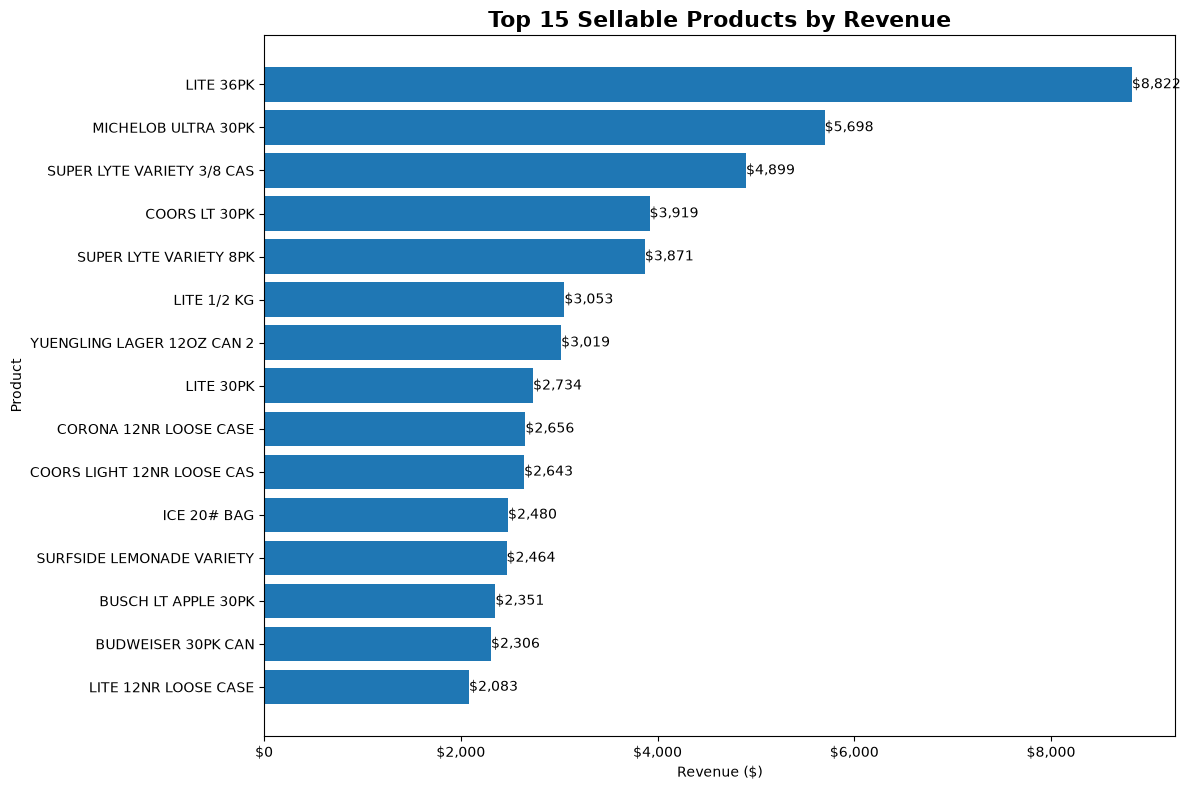

In [ ]:
from matplotlib.ticker import FuncFormatter

top15_revenue = product_summary.sort_values(
    "total_revenue",
    ascending=False
).head(15)

plt.figure(figsize=(12, 8))

bars = plt.barh(
    top15_revenue["description"],
    top15_revenue["total_revenue"]
)

plt.gca().invert_yaxis()

plt.title("Top 15 Sellable Products by Revenue", fontsize=16, fontweight="bold")
plt.xlabel("Revenue ($)")
plt.ylabel("Product")

plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"${x:,.0f}")
)

for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f"${width:,.0f}",
        va="center"
    )

plt.tight_layout()
plt.show()

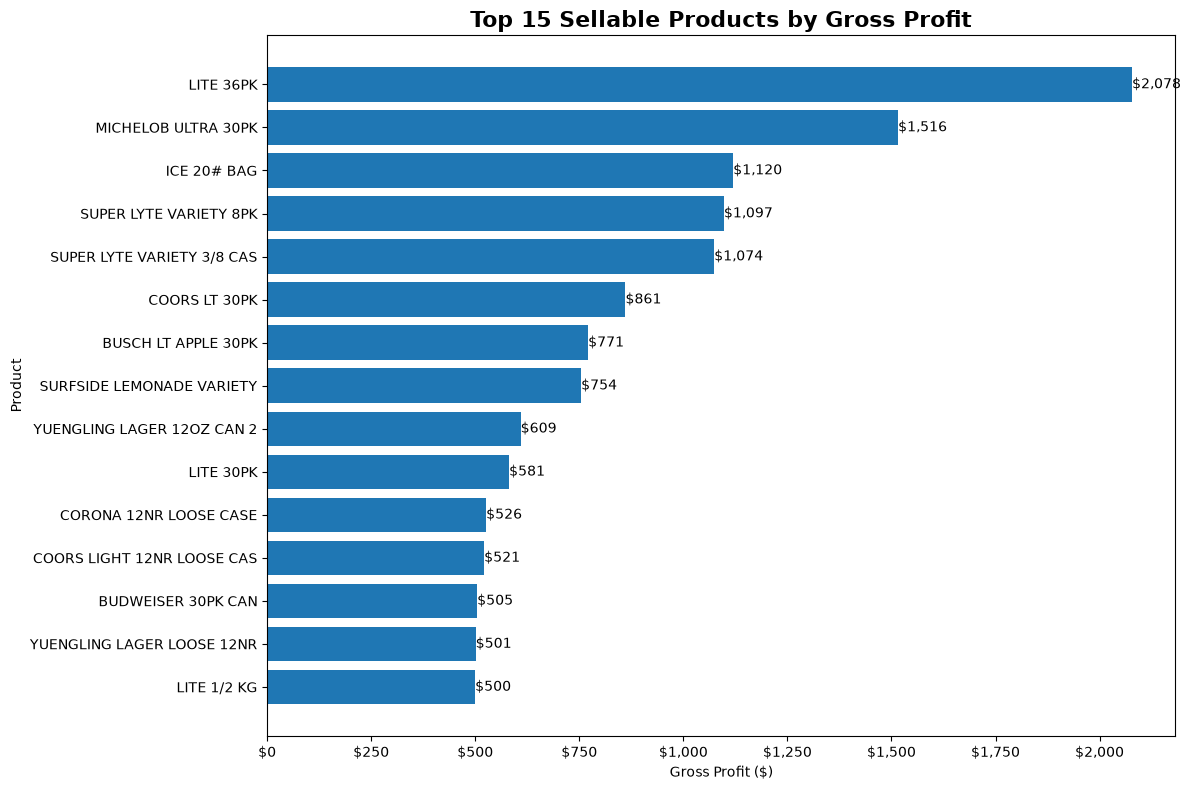

In [ ]:
from matplotlib.ticker import FuncFormatter

top15_profit = product_summary.sort_values(
    "total_profit",
    ascending=False
).head(15)

plt.figure(figsize=(12, 8))

bars = plt.barh(
    top15_profit["description"],
    top15_profit["total_profit"]
)

plt.gca().invert_yaxis()

plt.title("Top 15 Sellable Products by Gross Profit", fontsize=16, fontweight="bold")
plt.xlabel("Gross Profit ($)")
plt.ylabel("Product")

plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"${x:,.0f}")
)

for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f"${width:,.0f}",
        va="center"
    )

plt.tight_layout()
plt.show()

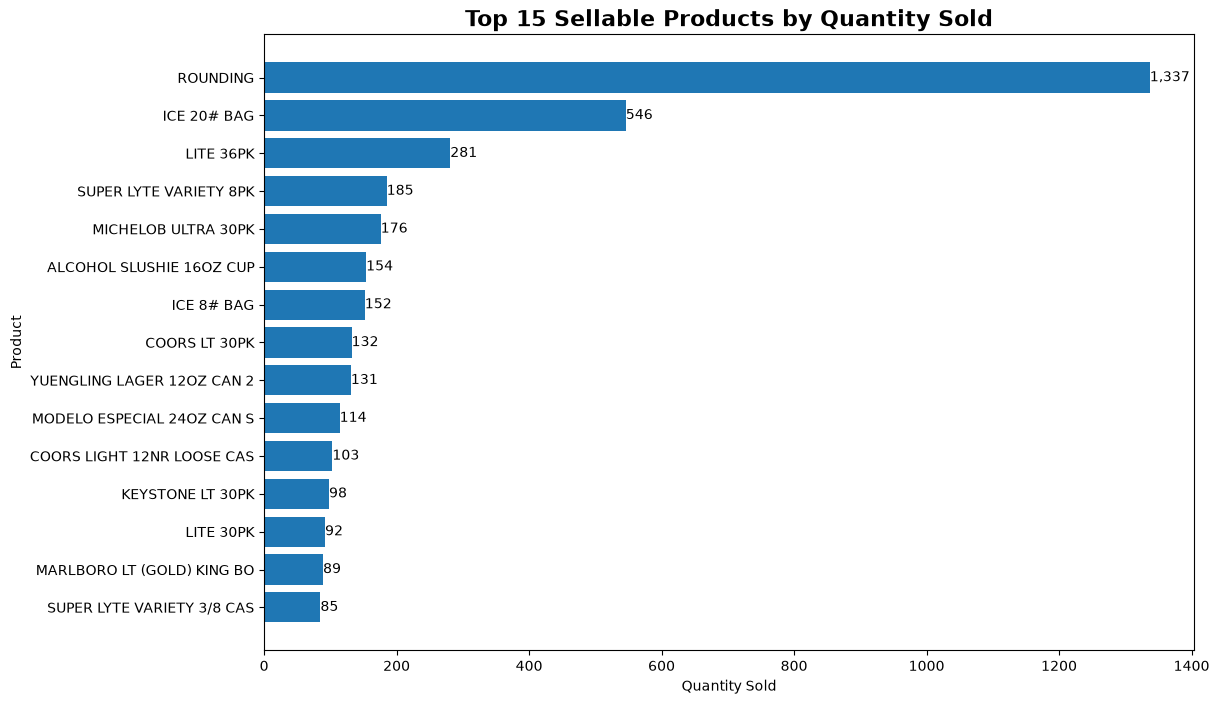

In [ ]:
top15_quantity = product_summary.sort_values(
    "total_quantity",
    ascending=False
).head(15)

plt.figure(figsize=(12, 8))

bars = plt.barh(
    top15_quantity["description"],
    top15_quantity["total_quantity"]
)

plt.gca().invert_yaxis()

plt.title("Top 15 Sellable Products by Quantity Sold", fontsize=16, fontweight="bold")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")

for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f"{width:,.0f}",
        va="center"
    )


In [ ]:
# Products with at least $500 in revenue
# sorted by lowest profit margin

low_margin_products = (
    product_summary[product_summary["total_revenue"] >= 500]
    .sort_values("profit_margin")
)

low_margin_products[
    [
        "description",
        "total_revenue",
        "total_profit",
        "profit_margin"
    ]
].head(20)

,description,total_revenue,total_profit,profit_margin
1577,MARLBORO ULTRA LT (SILVER),513.84,38.52,0.0750
1569,MARLBORO LT (GOLD) KING BO,1156.11,98.79,0.0855
1589,MARLBORO RED KING BOX PACK,584.55,49.95,0.0855
446,YUENGLING TRAD LAGER 1/2 K,931.93,137.43,0.1475
8,LITE 1/2 KG,3052.77,499.77,0.1637
909,STELLA ARTOIS 1/2 KG,1034.95,169.95,0.1642
1052,LANDSHARK 1/2 KG,505.97,88.97,0.1758
451,YUENGLING LAGER LT 12CAN C,1900.73,336.73,0.1772
708,COORS LIGHT 1/2 KG,834.84,153.84,0.1843
22,LITE 12NR 4/6PK CASE,1385.58,255.78,0.1846


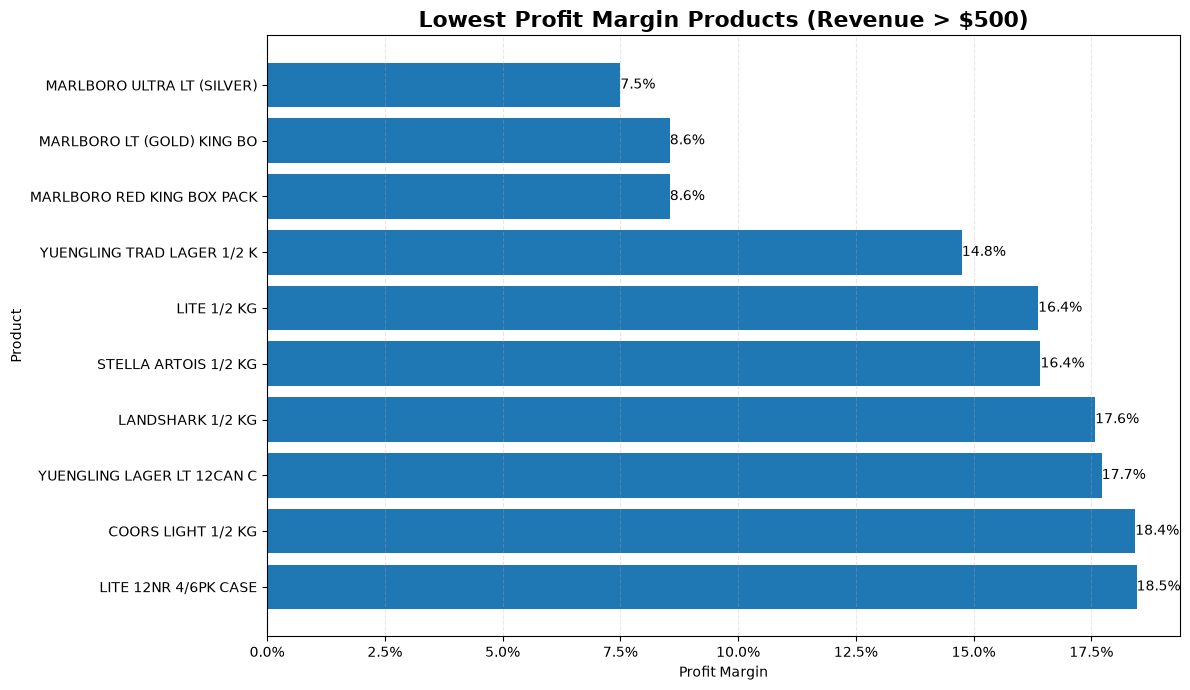

In [ ]:
from matplotlib.ticker import PercentFormatter

top10_low_margin = low_margin_products.head(10)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    top10_low_margin["description"],
    top10_low_margin["profit_margin"]
)

plt.gca().invert_yaxis()

plt.title(
    "Lowest Profit Margin Products (Revenue > $500)",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Profit Margin")
plt.ylabel("Product")

plt.gca().xaxis.set_major_formatter(PercentFormatter(1))

for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height()/2,
        f"{width:.1%}",
        va="center"
    )

plt.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Rank products (1 = best)

product_summary["revenue_rank"] = product_summary["total_revenue"].rank(
    ascending=False,
    method="dense"
)

product_summary["profit_rank"] = product_summary["total_profit"].rank(
    ascending=False,
    method="dense"
)

product_summary["volume_rank"] = product_summary["total_quantity"].rank(
    ascending=False,
    method="dense"
)

In [ ]:
product_summary["overall_score"] = (
    product_summary["revenue_rank"] +
    product_summary["profit_rank"] +
    product_summary["volume_rank"]
)

product_summary = product_summary.sort_values("overall_score")

product_summary.head(20)

,inventory_number,description,total_quantity,total_revenue,total_cost,total_profit,transactions,profit_margin,revenue_rank,profit_rank,volume_rank,overall_score
20,00236,LITE 36PK,281,8822.02,6744.00,2078.02,31,0.2355,1.0,1.0,3.0,5.0
85,10230U,MICHELOB ULTRA 30PK,176,5698.37,4182.40,1515.97,34,0.2660,2.0,2.0,5.0,9.0
1112,650941*8,SUPER LYTE VARIETY 8PK,185,3870.55,2773.15,1097.40,28,0.2835,5.0,4.0,4.0,13.0
1563,I20,ICE 20# BAG,546,2479.54,1359.75,1119.79,30,0.4516,11.0,3.0,2.0,16.0
714,35930,COORS LT 30PK,132,3918.68,3057.80,860.88,31,0.2197,4.0,6.0,8.0,18.0
1111,650941,SUPER LYTE VARIETY 3/8 CAS,85,4899.15,3825.00,1074.15,26,0.2193,3.0,5.0,15.0,23.0
450,21024,YUENGLING LAGER 12OZ CAN 2,131,3019.49,2410.40,609.09,34,0.2017,7.0,9.0,9.0,25.0
19,00230,LITE 30PK,92,2734.08,2152.80,581.28,32,0.2126,8.0,10.0,13.0,31.0
717,35944,COORS LIGHT 12NR LOOSE CAS,103,2643.23,2121.80,521.43,36,0.1973,10.0,12.0,11.0,33.0
1414,9997,BUSCH LT APPLE 30PK,79,2351.21,1580.00,771.21,9,0.3280,13.0,7.0,17.0,37.0


In [ ]:
def classify(score):
    if score <= 30:
        return "High Performer"
    elif score <= 100:
        return "Core Product"
    elif score <= 250:
        return "Growth Opportunity"
    else:
        return "Low Performer"

product_summary["performance_category"] = (
    product_summary["overall_score"]
    .apply(classify)
)

product_summary.head()

,inventory_number,description,total_quantity,total_revenue,total_cost,total_profit,transactions,profit_margin,revenue_rank,profit_rank,volume_rank,overall_score,performance_category
20,00236,LITE 36PK,281,8822.02,6744.00,2078.02,31,0.2355,1.0,1.0,3.0,5.0,High Performer
85,10230U,MICHELOB ULTRA 30PK,176,5698.37,4182.40,1515.97,34,0.2660,2.0,2.0,5.0,9.0,High Performer
1112,650941*8,SUPER LYTE VARIETY 8PK,185,3870.55,2773.15,1097.40,28,0.2835,5.0,4.0,4.0,13.0,High Performer
1563,I20,ICE 20# BAG,546,2479.54,1359.75,1119.79,30,0.4516,11.0,3.0,2.0,16.0,High Performer
714,35930,COORS LT 30PK,132,3918.68,3057.80,860.88,31,0.2197,4.0,6.0,8.0,18.0,High Performer


In [ ]:
product_summary["performance_category"].value_counts()

performance_category
Low Performer         1538
Growth Opportunity      64
Core Product            20
High Performer           7
Name: count, dtype: int64

In [ ]:
abc = product_summary.sort_values(
    "total_revenue",
    ascending=False
).copy()

abc.head()

,inventory_number,description,total_quantity,total_revenue,total_cost,total_profit,transactions,profit_margin,revenue_rank,profit_rank,volume_rank,overall_score,performance_category
20,00236,LITE 36PK,281,8822.02,6744.00,2078.02,31,0.2355,1.0,1.0,3.0,5.0,High Performer
85,10230U,MICHELOB ULTRA 30PK,176,5698.37,4182.40,1515.97,34,0.2660,2.0,2.0,5.0,9.0,High Performer
1111,650941,SUPER LYTE VARIETY 3/8 CAS,85,4899.15,3825.00,1074.15,26,0.2193,3.0,5.0,15.0,23.0,High Performer
714,35930,COORS LT 30PK,132,3918.68,3057.80,860.88,31,0.2197,4.0,6.0,8.0,18.0,High Performer
1112,650941*8,SUPER LYTE VARIETY 8PK,185,3870.55,2773.15,1097.40,28,0.2835,5.0,4.0,4.0,13.0,High Performer


In [ ]:
abc["cumulative_revenue"] = abc["total_revenue"].cumsum()

total_revenue = abc["total_revenue"].sum()

abc["cumulative_percent"] = (
    abc["cumulative_revenue"] / total_revenue
)

abc.head()

,inventory_number,description,total_quantity,total_revenue,total_cost,total_profit,transactions,profit_margin,revenue_rank,profit_rank,volume_rank,overall_score,performance_category,cumulative_revenue,cumulative_percent
20,00236,LITE 36PK,281,8822.02,6744.00,2078.02,31,0.2355,1.0,1.0,3.0,5.0,High Performer,8822.02,0.038745
85,10230U,MICHELOB ULTRA 30PK,176,5698.37,4182.40,1515.97,34,0.2660,2.0,2.0,5.0,9.0,High Performer,14520.39,0.063772
1111,650941,SUPER LYTE VARIETY 3/8 CAS,85,4899.15,3825.00,1074.15,26,0.2193,3.0,5.0,15.0,23.0,High Performer,19419.54,0.085288
714,35930,COORS LT 30PK,132,3918.68,3057.80,860.88,31,0.2197,4.0,6.0,8.0,18.0,High Performer,23338.22,0.102499
1112,650941*8,SUPER LYTE VARIETY 8PK,185,3870.55,2773.15,1097.40,28,0.2835,5.0,4.0,4.0,13.0,High Performer,27208.77,0.119498


In [ ]:
def abc_class(percent):

    if percent <= 0.80:
        return "A"

    elif percent <= 0.95:
        return "B"

    else:
        return "C"

abc["ABC_Class"] = abc["cumulative_percent"].apply(abc_class)

abc.head(20)

,inventory_number,description,total_quantity,total_revenue,total_cost,total_profit,transactions,profit_margin,revenue_rank,profit_rank,volume_rank,overall_score,performance_category,cumulative_revenue,cumulative_percent,ABC_Class
20,00236,LITE 36PK,281,8822.02,6744.00,2078.02,31,0.2355,1.0,1.0,3.0,5.0,High Performer,8822.02,0.038745,A
85,10230U,MICHELOB ULTRA 30PK,176,5698.37,4182.40,1515.97,34,0.2660,2.0,2.0,5.0,9.0,High Performer,14520.39,0.063772,A
1111,650941,SUPER LYTE VARIETY 3/8 CAS,85,4899.15,3825.00,1074.15,26,0.2193,3.0,5.0,15.0,23.0,High Performer,19419.54,0.085288,A
714,35930,COORS LT 30PK,132,3918.68,3057.80,860.88,31,0.2197,4.0,6.0,8.0,18.0,High Performer,23338.22,0.102499,A
1112,650941*8,SUPER LYTE VARIETY 8PK,185,3870.55,2773.15,1097.40,28,0.2835,5.0,4.0,4.0,13.0,High Performer,27208.77,0.119498,A
8,00202,LITE 1/2 KG,23,3052.77,2553.00,499.77,10,0.1637,6.0,15.0,54.0,75.0,Core Product,30261.54,0.132905,A
450,21024,YUENGLING LAGER 12OZ CAN 2,131,3019.49,2410.40,609.09,34,0.2017,7.0,9.0,9.0,25.0,High Performer,33281.03,0.146166,A
19,00230,LITE 30PK,92,2734.08,2152.80,581.28,32,0.2126,8.0,10.0,13.0,31.0,Core Product,36015.11,0.158174,A
694,35742,CORONA 12NR LOOSE CASE,72,2656.28,2130.15,526.13,29,0.1981,9.0,11.0,22.0,42.0,Core Product,38671.39,0.169840,A
717,35944,COORS LIGHT 12NR LOOSE CAS,103,2643.23,2121.80,521.43,36,0.1973,10.0,12.0,11.0,33.0,Core Product,41314.62,0.181449,A


In [ ]:
abc["ABC_Class"].value_counts()

ABC_Class
C    919
B    371
A    339
Name: count, dtype: int64

In [ ]:
abc.to_csv("../data/cleaned/abc_analysis.csv", index=False)

print("ABC Analysis saved.")

ABC Analysis saved.
